# Обучение DnCNN-Lite (Shumodav)

Запускай ячейки по одной сверху вниз. Инструкция: `docs/TRAINING_COLAB.md`. Включи GPU: Среда выполнения → Сменить среду выполнения → T4 GPU.

## 1. Проверка видеокарты

In [1]:
!nvidia-smi
import torch
print("CUDA доступна:", torch.cuda.is_available())

Sun Oct 11 13:35:48 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   37C    P8              9W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

## 2. Google Drive для чекпойнтов

In [2]:
from google.colab import drive
drive.mount('/content/drive')
CKPT = '/content/drive/MyDrive/shumodav_ckpt'
!mkdir -p {CKPT}

Mounted at /content/drive


## 3. Код проекта

In [3]:
!rm -rf /content/shumodav
!git clone -b v2 https://github.com/mkass420/shumodav.git /content/shumodav
%cd /content/shumodav
!pip install -q -e . --no-deps --ignore-requires-python
!pip install -q scikit-image tqdm

Cloning into '/content/shumodav'...
remote: Enumerating objects: 130, done.
remote: Counting objects: 100% (130/130), done.
remote: Compressing objects: 100% (97/97), done.
remote: Total 130 (delta 23), reused 127 (delta 20), pack-reused 0 (from 0)
Receiving objects: 100% (130/130), 201.66 KiB | 8.07 MiB/s, done.
Resolving deltas: 100% (23/23), done.
/content/shumodav
  Installing build dependencies ... done
  Checking if build backend supports build_editable ... done
  Getting requirements to build editable ... done
  Preparing editable metadata (pyproject.toml) ... done
  Building editable for shumodav (pyproject.toml) ... done


## 4. Данные

In [4]:
!python scripts/get_data.py
!ls data/train400 | wc -l   # должно быть 400
!ls data/bsd68 | wc -l      # должно быть 68

Cloning into '/tmp/tmpy9ht0697/dncnn'...
remote: Enumerating objects: 677, done.
remote: Counting objects: 100% (677/677), done.
remote: Compressing objects: 100% (654/654), done.
remote: Total 677 (delta 18), reused 663 (delta 16), pack-reused 0 (from 0)
Receiving objects: 100% (677/677), 125.66 MiB | 30.48 MiB/s, done.
Resolving deltas: 100% (18/18), done.
Updating files: 100% (841/841), done.
train400 400
bsd68 68
set12 12
400
68


## 5. Пробный запуск (1–2 минуты)

In [5]:
!python -m shumodav.nn.train --smoke --device cuda --out /content/smoke.pth

iter 25 | loss 0.05817 | val PSNR: gaussian 18.6 | salt_pepper 14.6 | speckle 18.1 | poisson 17.2
iter 50 | loss 0.01229 | val PSNR: gaussian 21.5 | salt_pepper 16.7 | speckle 21.6 | poisson 20.0
Готово за 0.6 мин. Лучший средний PSNR: 19.96


## 6. Обучение (20–40 минут)

Если сессия оборвалась: запусти ячейки 1–4 и эту ещё раз, `--resume` продолжит с чекпойнта на Drive.

In [6]:
!python -m shumodav.nn.train --data data/train400 --val data/bsd68 \
    --iters 15000 --batch 128 --lr 1e-3 --device cuda \
    --ckpt-dir {CKPT} --out {CKPT}/custom_cnn.pth --resume

iter 1000 | loss 0.00465 | val PSNR: gaussian 25.1 | salt_pepper 27.2 | speckle 25.5 | poisson 24.4
iter 2000 | loss 0.00269 | val PSNR: gaussian 27.2 | salt_pepper 30.2 | speckle 27.8 | poisson 26.6
iter 3000 | loss 0.00236 | val PSNR: gaussian 27.6 | salt_pepper 34.2 | speckle 27.8 | poisson 26.6
iter 4000 | loss 0.00217 | val PSNR: gaussian 27.0 | salt_pepper 35.3 | speckle 27.2 | poisson 26.1
iter 5000 | loss 0.00210 | val PSNR: gaussian 27.7 | salt_pepper 34.7 | speckle 28.2 | poisson 27.0
iter 6000 | loss 0.00201 | val PSNR: gaussian 23.0 | salt_pepper 30.0 | speckle 24.4 | poisson 23.3
iter 7000 | loss 0.00196 | val PSNR: gaussian 27.0 | salt_pepper 36.7 | speckle 27.1 | poisson 25.8
iter 8000 | loss 0.00190 | val PSNR: gaussian 27.6 | salt_pepper 37.3 | speckle 28.1 | poisson 26.7
iter 9000 | loss 0.00186 | val PSNR: gaussian 27.7 | salt_pepper 36.2 | speckle 28.2 | poisson 27.0
iter 10000 | loss 0.00173 | val PSNR: gaussian 28.4 | salt_pepper 38.5 | speckle 28.9 | poisson 27.6

## 7. График обучения

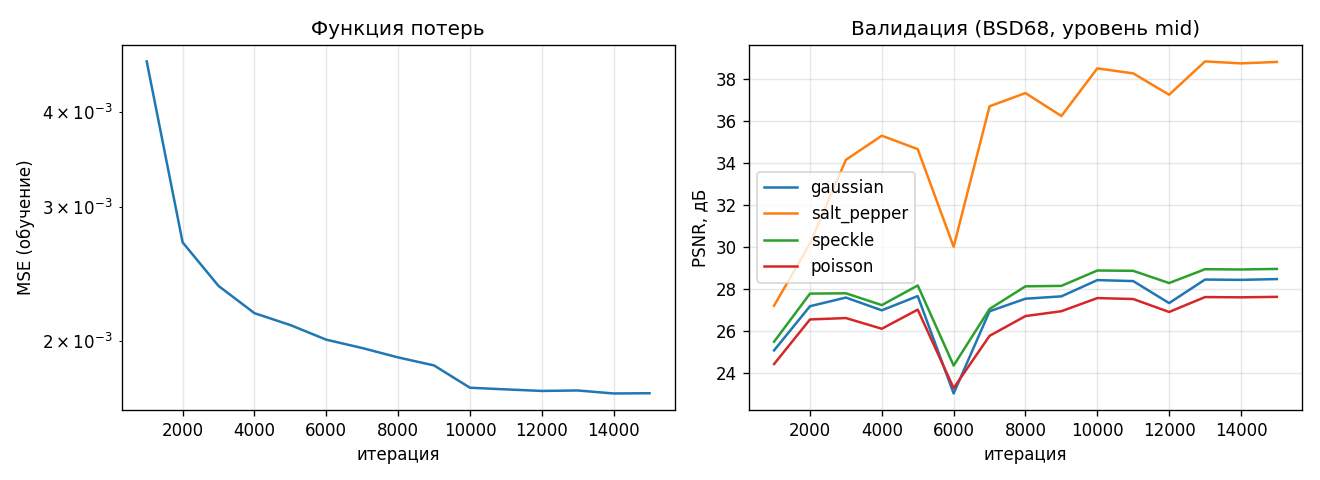

,iter,loss,val_psnr_gaussian,val_psnr_salt_pepper,val_psnr_speckle,val_psnr_poisson,val_psnr_mean
10,11000,0.001726,28.392470,38.274919,28.881325,27.539619,30.772083
11,12000,0.001718,27.345726,37.259223,28.298988,26.923198,29.956784
12,13000,0.001720,28.465580,38.845109,28.956981,27.631952,30.974906
13,14000,0.001704,28.450529,38.751399,28.944695,27.620245,30.941717
14,15000,0.001706,28.487866,38.819121,28.971186,27.642295,30.980117


In [7]:
from IPython.display import Image, display
import pandas as pd
display(Image(f'{CKPT}/train_curve.png'))
pd.read_csv(f'{CKPT}/train_log.csv').tail(5)

## 8. Скачать результаты

In [8]:
from google.colab import files
for name in ['custom_cnn.pth', 'train_log.csv', 'train_curve.png']:
    files.download(f'{CKPT}/{name}')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>